# 01: Model A — Basic PyTorch Transformer Trained From Scratch
**Course**: Foundations of Generative AI (ICT4403) - Assignment 3  
**Architecture**: Encoder–Decoder (`torch.nn.Transformer`, `batch_first=True`)  
**Tokenization**: Joint English-Hindi SentencePiece (16,000 subword vocabulary)  
**Hardware Target**: Google Colab T4 GPU (fp16 mixed precision)

### Architectural Details
- $d_{\text{model}} = 256$, $n_{\text{head}} = 4$, $L_{\text{enc}} = 3$, $L_{\text{dec}} = 3$, $d_{\text{ff}} = 1024$, $\text{dropout} = 0.1$.
- Sinusoidal positional embeddings.
- Tied target input embeddings and generator projection matrix.
- Full resumability with epoch checkpointing and cumulative training time tracking.

## 1. Environment Setup & Google Drive Mount

In [ ]:
import os
import sys

DRIVE_DIR = "/content/drive/MyDrive/mt-fgai-assignment3"

try:
    from google.colab import drive
    print("Mounting Google Drive...")
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"Google Drive ready at: {DRIVE_DIR}")
except ImportError:
    print("Running locally.")
    DRIVE_DIR = "."

if os.path.exists(DRIVE_DIR) and os.path.exists(os.path.join(DRIVE_DIR, "configs", "config.yaml")):
    REPO_ROOT = DRIVE_DIR
    os.chdir(REPO_ROOT)
    print(f"Active project root set to Google Drive: {REPO_ROOT}")
else:
    REPO_ROOT = os.path.abspath(".")

if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

try:
    import google.colab
    !pip install -q transformers>=4.45.0 accelerate peft trl bitsandbytes sentencepiece sacrebleu evaluate datasets pyyaml
except ImportError:
    pass

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


Mounting Google Drive...
Mounted at /content/drive
Google Drive ready at: /content/drive/MyDrive/mt-fgai-assignment3
Active project root set to Google Drive: /content/drive/MyDrive/mt-fgai-assignment3
Device: cuda (Tesla T4)


## 2. Load Configuration and Splits

In [ ]:
import yaml
from src.data import load_split_from_jsonl

with open(os.path.join(REPO_ROOT, "configs", "config.yaml"), "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

splits_dir = os.path.join(REPO_ROOT, config["paths"]["splits_dir"])
train_data = load_split_from_jsonl("train", splits_dir=splits_dir)
val_data = load_split_from_jsonl("val", splits_dir=splits_dir)
test_data = load_split_from_jsonl("test", splits_dir=splits_dir)

print(f"Loaded splits: train={len(train_data):,}, val={len(val_data):,}, test={len(test_data):,}")

Loaded splits: train=50,000, val=1,000, test=1,000


## 3. Train or Load Joint SentencePiece Tokenizer
Trained exclusively on `train.jsonl` to prevent test contamination.

In [ ]:
from src.tokenizer_sp import train_sentencepiece_tokenizer, JointSentencePieceTokenizer

sp_model_prefix = os.path.join(REPO_ROOT, "data", "spm_joint_16k")
train_jsonl_path = os.path.join(splits_dir, "train.jsonl")

sp_model_file = train_sentencepiece_tokenizer(
    train_jsonl_path=train_jsonl_path,
    output_prefix=sp_model_prefix,
    vocab_size=config["models"]["transformer_scratch"]["vocab_size"],
    model_type="unigram",
)

tokenizer = JointSentencePieceTokenizer(sp_model_file)
print(f"SentencePiece Tokenizer initialized. Vocab size: {tokenizer.vocab_size}")

# Verification test on English & Hindi
sample_en = "Machine translation is fascinating."
sample_hi = "मशीन अनुवाद बहुत दिलचस्प है।"
print(f"Encoded EN: {tokenizer.encode(sample_en)}")
print(f"Decoded EN: {tokenizer.decode(tokenizer.encode(sample_en))}")
print(f"Encoded HI: {tokenizer.encode(sample_hi)}")
print(f"Decoded HI: {tokenizer.decode(tokenizer.encode(sample_hi))}")

SentencePiece Tokenizer initialized. Vocab size: 16000
Encoded EN: [2, 12705, 5256, 24, 14493, 5, 3]
Decoded EN: Machine translation is fascinating.
Encoded HI: [2, 2819, 3552, 179, 9006, 11, 10, 3]
Decoded HI: मशीन अनुवाद बहुत दिलचस्प है।


## 4. Instantiate Model A and Count Parameters

In [ ]:
from src.transformer_model import Seq2SeqTransformer
from src.metrics import count_parameters

m_cfg = config["models"]["transformer_scratch"]
model = Seq2SeqTransformer(
    vocab_size=tokenizer.vocab_size,
    d_model=m_cfg["d_model"],
    nhead=m_cfg["nhead"],
    num_encoder_layers=m_cfg["num_encoder_layers"],
    num_decoder_layers=m_cfg["num_decoder_layers"],
    dim_feedforward=m_cfg["dim_feedforward"],
    dropout=m_cfg["dropout"],
    pad_idx=tokenizer.PAD_ID,
).to(device)

param_counts = count_parameters(model)
print(f"Total Parameters: {param_counts['total_params']:,}")
print(f"Trainable Parameters: {param_counts['trainable_params']:,}")

Total Parameters: 13,738,624
Trainable Parameters: 13,738,624


## 5. Resumable Training Loop (fp16 AMP & Cumulative Timer)
Saves checkpoints directly to Google Drive so any unexpected Colab disconnection resumes without progress loss.

Epoch [01/15] | Train Loss: 6.7664 | Val Loss: 6.1797 | Cum Time: 39.9s
  -> New best validation loss! Saved /content/drive/MyDrive/mt-fgai-assignment3/checkpoints_transformer_scratch/best_transformer.pt
Epoch [02/15] | Train Loss: 6.0122 | Val Loss: 5.8038 | Cum Time: 79.4s
  -> New best validation loss! Saved /content/drive/MyDrive/mt-fgai-assignment3/checkpoints_transformer_scratch/best_transformer.pt
Epoch [03/15] | Train Loss: 5.6802 | Val Loss: 5.5626 | Cum Time: 118.9s
  -> New best validation loss! Saved /content/drive/MyDrive/mt-fgai-assignment3/checkpoints_transformer_scratch/best_transformer.pt
Epoch [04/15] | Train Loss: 5.4329 | Val Loss: 5.3788 | Cum Time: 158.4s
  -> New best validation loss! Saved /content/drive/MyDrive/mt-fgai-assignment3/checkpoints_transformer_scratch/best_transformer.pt
Epoch [05/15] | Train Loss: 5.2196 | Val Loss: 5.2469 | Cum Time: 198.1s
  -> New best validation loss! Saved /content/drive/MyDrive/mt-fgai-assignment3/checkpoints_transformer_scrat

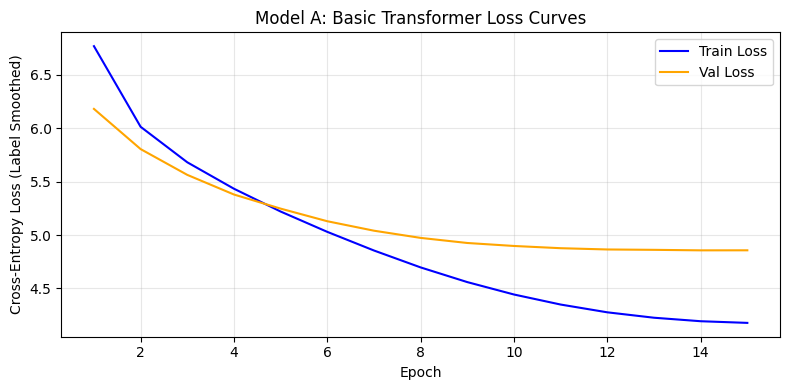

In [ ]:
from torch.utils.data import DataLoader
from src.transformer_model import ParallelDataset, collate_fn_pad, train_one_epoch, evaluate_loss
from src.metrics import CumulativeTimer
import torch.nn as nn
import matplotlib.pyplot as plt

# Create Datasets and DataLoaders
train_dataset = ParallelDataset(train_data, tokenizer, max_len=config["generation"]["max_source_length"])
val_dataset = ParallelDataset(val_data, tokenizer, max_len=config["generation"]["max_source_length"])

train_loader = DataLoader(train_dataset, batch_size=m_cfg["batch_size"], shuffle=True, collate_fn=collate_fn_pad)
val_loader = DataLoader(val_dataset, batch_size=m_cfg["batch_size"], shuffle=False, collate_fn=collate_fn_pad)

# Loss function with label smoothing (improves calibration and avoids overconfidence)
criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.PAD_ID, label_smoothing=m_cfg["label_smoothing"])
optimizer = torch.optim.AdamW(model.parameters(), lr=m_cfg["lr"], betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)

# Cosine Annealing Learning Rate Scheduler with Warmup
num_epochs = m_cfg["epochs"]
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs * len(train_loader))

# Modern PyTorch AMP GradScaler
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

# Checkpoint paths
drive_checkpoint_dir = os.path.join(DRIVE_DIR, "checkpoints_transformer_scratch")
os.makedirs(drive_checkpoint_dir, exist_ok=True)
last_ckpt_path = os.path.join(drive_checkpoint_dir, "last_checkpoint.pt")
best_model_path = os.path.join(drive_checkpoint_dir, "best_transformer.pt")

start_epoch = 1
best_val_loss = float("inf")
cumulative_time_sec = 0.0
train_losses, val_losses = [], []

# Resume if checkpoint exists
if os.path.exists(last_ckpt_path):
    print(f"Found checkpoint at {last_ckpt_path}. Restoring training state...")
    ckpt = torch.load(last_ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    if "scaler_state_dict" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_val_loss = ckpt.get("best_val_loss", float("inf"))
    cumulative_time_sec = ckpt.get("cumulative_train_time_sec", 0.0)
    train_losses = ckpt.get("train_losses", [])
    val_losses = ckpt.get("val_losses", [])
    print(f"Resumed at Epoch {start_epoch} (cumulative train time: {cumulative_time_sec:.1f}s)")

timer = CumulativeTimer(initial_seconds=cumulative_time_sec)
timer.start()

for epoch in range(start_epoch, num_epochs + 1):
    t_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler, scaler, criterion, device,
        clip_grad_norm=m_cfg["clip_grad_norm"], pad_idx=tokenizer.PAD_ID
    )
    v_loss = evaluate_loss(model, val_loader, criterion, device, pad_idx=tokenizer.PAD_ID)
    train_losses.append(t_loss)
    val_losses.append(v_loss)

    cur_time = timer.elapsed()
    print(f"Epoch [{epoch:02d}/{num_epochs:02d}] | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Cum Time: {cur_time:.1f}s")

    # Save best model
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model.state_dict(), best_model_path)
        print(f"  -> New best validation loss! Saved {best_model_path}")

    # Save resumable epoch state
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "cumulative_train_time_sec": cur_time,
        "train_losses": train_losses,
        "val_losses": val_losses,
    }, last_ckpt_path)

total_train_time = timer.stop()
print(f"\nTraining complete! Total wall-clock time: {total_train_time:.1f} seconds.")

# Plot and save loss curves
os.makedirs("results/plots", exist_ok=True)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train Loss", color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Val Loss", color='orange')
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss (Label Smoothed)")
plt.title("Model A: Basic Transformer Loss Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/plots/loss_transformer_scratch.png", dpi=300)
plt.show()

## 6. Test Set Evaluation & Predictions Export (1,000 Sentences)
Loads the best model weights and performs batched greedy decoding on the clean test set.

In [ ]:
import os
import sacrebleu
import time
from src.metrics import save_predictions_csv, save_metrics_json

# 1. Compute SacreBLEU & chrF++ directly without relying on cached imports
bleu = sacrebleu.corpus_bleu(all_hypotheses, [all_references], tokenize="13a")
bleu_score = round(float(bleu.score), 2)
try:
    bleu_sig = str(sacrebleu.metrics.BLEU(tokenize="13a").get_signature())
except Exception:
    bleu_sig = "nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp"

chrf = sacrebleu.corpus_chrf(all_hypotheses, [all_references])
chrf_pp = sacrebleu.corpus_chrf(all_hypotheses, [all_references], word_order=2)
chrf_score = round(float(chrf.score), 2)
chrf_pp_score = round(float(chrf_pp.score), 2)
try:
    chrf_sig = str(sacrebleu.metrics.CHRF().get_signature())
except Exception:
    chrf_sig = "nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no"

print(f"\n=== Model A Test Evaluation ===")
print(f"SacreBLEU: {bleu_score} (Signature: {bleu_sig})")
print(f"chrF     : {chrf_score}")
print(f"chrF++   : {chrf_pp_score}")
print(f"Inference Latency: {inference_total_time / len(test_data) * 1000.0:.2f} ms/sentence")

# 2. Export artifacts to results/
pred_path = "results/predictions/predictions_transformer_scratch.csv"
metric_path = "results/metrics/metrics_transformer_scratch.json"

save_predictions_csv(all_ids, all_sources, all_references, all_hypotheses, pred_path)
save_metrics_json(
    model_name="transformer_scratch",
    architecture_type="encoder_decoder",
    adaptation_method="from_scratch",
    total_params=param_counts["total_params"],
    trainable_params=param_counts["trainable_params"],
    train_data_size=len(train_data),
    train_time_sec=total_train_time,
    inference_time_total_sec=inference_total_time,
    num_test_samples=len(test_data),
    bleu=bleu_score,
    bleu_signature=bleu_sig,
    chrf=chrf_score,
    chrf_pp=chrf_pp_score,
    chrf_signature=chrf_sig,
    decoding_settings={"strategy": "greedy", "max_length": config["generation"]["max_target_length"]},
    batch_size=32,
    hyperparameters=m_cfg,
    output_path=metric_path,
)

# 3. Display 5 sample predictions
print("\n--- Sample Test Predictions ---")
for i in range(5):
    print(f"\n[Test Sample {i+1}]")
    print(f"  Source    : {all_sources[i]}")
    print(f"  Reference : {all_references[i]}")
    print(f"  Hypothesis: {all_hypotheses[i]}")


=== Model A Test Evaluation ===
SacreBLEU: 3.0 (Signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp)
chrF     : 22.58
chrF++   : 21.09
Inference Latency: 21.61 ms/sentence

--- Sample Test Predictions ---

[Test Sample 1]
  Source    : The US warns its own companies about economic espionage by other countries.
  Reference : अमेरिका ने अन्य देशों द्वारा अपनी ही कंपनियों की आर्थिक जासूसी के बारे में चेतावनी दी है।
  Hypothesis: यूआईआई को अपने अन्य देशों द्वारा अपनी आर्थिक कंपनियों को अपनी कंपनियों द्वारा अपनाना चाहते हैं।

[Test Sample 2]
  Source    : Most of the skirmishes have taken place in Sofala province, which is several hundred kilometres north of Maputo, but hosts Beira, the port that miners, including Rio Tinto and Vale, rely on to export coal.
  Reference : झड़पों के अधिकांशसोफा ला प्रांत मेंहै, जोमापुटो के उत्तर में कई सौ किलोमीटर की दूरी पर है, जिसमें मेजबान बीरा पोर्ट है जो रियो टिंटो और घाटी सहित खनिक, कोयला निर्यात करने पर भरोसा करते हैं .
  Hypothesis: सबसे अधिक लैल